# Módulo 1 — Entregable integrador

Este notebook junta **NumPy** (cálculo), **Xarray** (datos con nombre),
**Pandas** (manejo del tiempo) y **Matplotlib** (figura final) en un solo
flujo. Es el mismo tipo de notebook que vamos a repetir en los módulos
siguientes.

Tiene dos partes:

- **📘 Secciones 1 a 6 (resueltas):** el flujo completo con la
  **temperatura** de la semana del 10 al 16 de marzo. Ejecútalas y léelas.
- **✍️ Sección 7 (tu entregable):** el mismo flujo, escrito por ti, para la
  **humedad relativa** de la semana siguiente.

**Datos:** temperatura horaria de 5 estaciones automáticas de SENAMHI en
Lima durante una semana (10 al 16 de marzo de 2025, hora local).

## 1. Leer los datos de SENAMHI (con sus huecos)

In [1]:
import json

import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

CARPETA = "../../../data/senamhi/"

# Lista de diccionarios: codigo, nombre, lat, lon, alt_m, archivo...
with open(CARPETA + "estaciones_lima.json", encoding="utf-8") as f:
    estaciones = json.load(f)

nombres = [e["nombre"] for e in estaciones]
tiempo = pd.date_range("2025-03-10", periods=24 * 7, freq="h")   # hora local de Perú


def leer_temperatura(archivo):
    d = pd.read_csv(CARPETA + archivo, sep=";", dtype=str)
    fechas = pd.to_datetime(d["Año"] + "-" + d["Mes"] + "-" + d["Día"] + " " + d["Hora"])
    valores = pd.to_numeric(d["Temperatura (°C)"], errors="coerce")   # "S/D" -> NaN
    return pd.Series(valores.values, index=fechas).reindex(tiempo)      # horas que faltan -> NaN


data = np.column_stack([leer_temperatura(e["archivo"]) for e in estaciones])

print("Forma del arreglo de temperatura (tiempo, estacion):", data.shape)
print("Horas sin dato en la semana:")
for nombre, n in zip(nombres, np.isnan(data).sum(axis=0)):
    print(f"  {nombre:22s} {n}")

Forma del arreglo de temperatura (tiempo, estacion): (168, 5)
Horas sin dato en la semana:
  San Martín de Porres   0
  Campo de Marte         2
  Von Humboldt           1
  Ceres                  0
  Ñaña                   1


## 2. Estructurar con Xarray (nombres + coordenadas + atributos)

In [2]:
ds = xr.Dataset(
    data_vars={
        "temperatura": (["tiempo", "estacion"], data, {
            "units": "degC",
            "long_name": "Temperatura del aire (estación automática)",
        }),
    },
    coords={
        "tiempo": tiempo,
        "estacion": nombres,
        "lat": ("estacion", [e["lat"] for e in estaciones]),
        "lon": ("estacion", [e["lon"] for e in estaciones]),
        "altura": ("estacion", [e["alt_m"] for e in estaciones], {"units": "m"}),
    },
    attrs={
        "title": "Temperatura horaria de 5 estaciones SENAMHI en Lima — Módulo 1",
        "source": "SENAMHI (https://www.senamhi.gob.pe/), hora local UTC-5",
        "Conventions": "Ad-hoc (no CF, ver Módulo 2)",
    },
)
ds

<xarray.Dataset> Size: 9kB
Dimensions:      (tiempo: 168, estacion: 5)
Coordinates:
  * tiempo       (tiempo) datetime64[us] 1kB 2025-03-10 ... 2025-03-16T23:00:00
  * estacion     (estacion) <U20 400B 'San Martín de Porres' ... 'Ñaña'
    lat          (estacion) float64 40B -12.01 -12.07 -12.08 -12.03 -11.99
    lon          (estacion) float64 40B -77.08 -77.04 -76.94 -76.93 -76.84
    altura       (estacion) int64 40B 56 117 247 339 553
Data variables:
    temperatura  (tiempo, estacion) float64 7kB 23.6 22.4 22.4 ... 20.9 22.0
Attributes:
    title:        Temperatura horaria de 5 estaciones SENAMHI en Lima — Módulo 1
    source:       SENAMHI (https://www.senamhi.gob.pe/), hora local UTC-5
    Conventions:  Ad-hoc (no CF, ver Módulo 2)

## 3. Estadísticas con NumPy (a través de los métodos de Xarray, que usan NumPy por debajo)

In [3]:
promedio_por_estacion = ds["temperatura"].mean(dim="tiempo")
maximo_por_estacion = ds["temperatura"].max(dim="tiempo")
minimo_por_estacion = ds["temperatura"].min(dim="tiempo")

resumen = pd.DataFrame({
    "promedio_degC": promedio_por_estacion.to_pandas().round(2),
    "maximo_degC": maximo_por_estacion.to_pandas().round(2),
    "minimo_degC": minimo_por_estacion.to_pandas().round(2),
})
resumen

,promedio_degC,maximo_degC,minimo_degC
estacion,,,
San Martín de Porres,23.20,27.2,19.9
Campo de Marte,22.59,27.5,19.5
Von Humboldt,23.71,31.1,18.7
Ceres,24.47,31.4,20.1
Ñaña,24.10,30.3,19.8


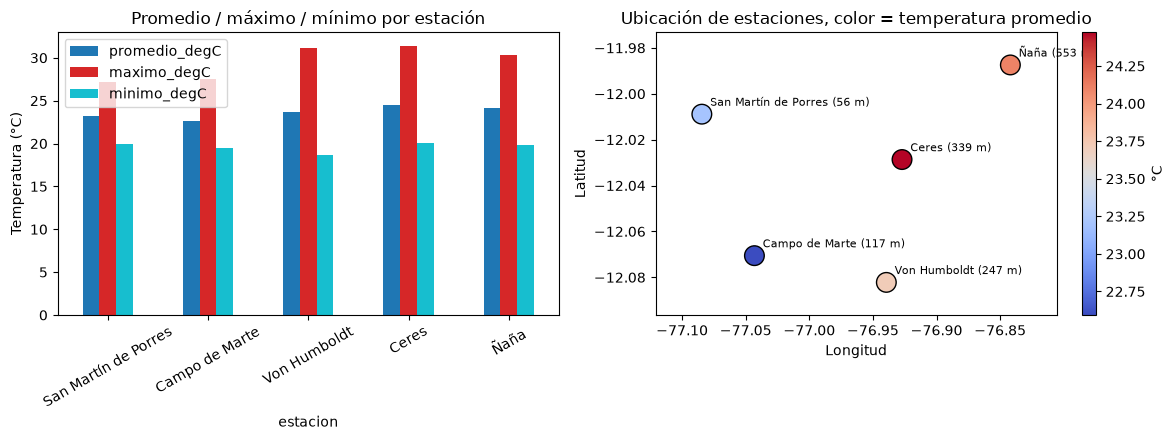

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

resumen.plot(kind="bar", ax=axes[0], color=["tab:blue", "tab:red", "tab:cyan"])
axes[0].set_ylabel("Temperatura (°C)")
axes[0].set_title("Promedio / máximo / mínimo por estación")
axes[0].tick_params(axis="x", rotation=30)

# "Mapa" simple con las coordenadas reales de cada estación (scatter, sin cartopy
# -- ese detalle se ve en el Módulo 4 con datos de grilla real)
sc = axes[1].scatter(ds["lon"], ds["lat"], c=promedio_por_estacion.values,
                      s=200, cmap="coolwarm", edgecolor="k")
for nombre in nombres:
    etiqueta = f"{nombre} ({int(ds['altura'].sel(estacion=nombre))} m)"
    axes[1].annotate(etiqueta, (ds["lon"].sel(estacion=nombre), ds["lat"].sel(estacion=nombre)),
                      textcoords="offset points", xytext=(6, 6), fontsize=8)
axes[1].margins(0.15)   # espacio para que no se corten los nombres
axes[1].set_xlabel("Longitud")
axes[1].set_ylabel("Latitud")
axes[1].set_title("Ubicación de estaciones, color = temperatura promedio")
plt.colorbar(sc, ax=axes[1], label="°C")

fig.tight_layout()
plt.show()

## 4. Manejo temporal con Pandas: promedio diario del dominio

In [5]:
promedio_espacial = ds["temperatura"].mean(dim="estacion").to_series()
promedio_espacial.index.name = "tiempo"

diario = promedio_espacial.resample("1D").agg(["mean", "min", "max"])
diario.columns = ["promedio", "minimo", "maximo"]
diario

,promedio,minimo,maximo
tiempo,,,
2025-03-10,24.400000,21.60,29.12
2025-03-11,23.620625,20.34,27.92
2025-03-12,23.060000,20.56,26.34
2025-03-13,23.081250,20.32,26.88
2025-03-14,23.375833,20.76,27.20
2025-03-15,24.244375,22.12,28.16
2025-03-16,23.539167,21.14,28.16


## 5. Figura final con Matplotlib

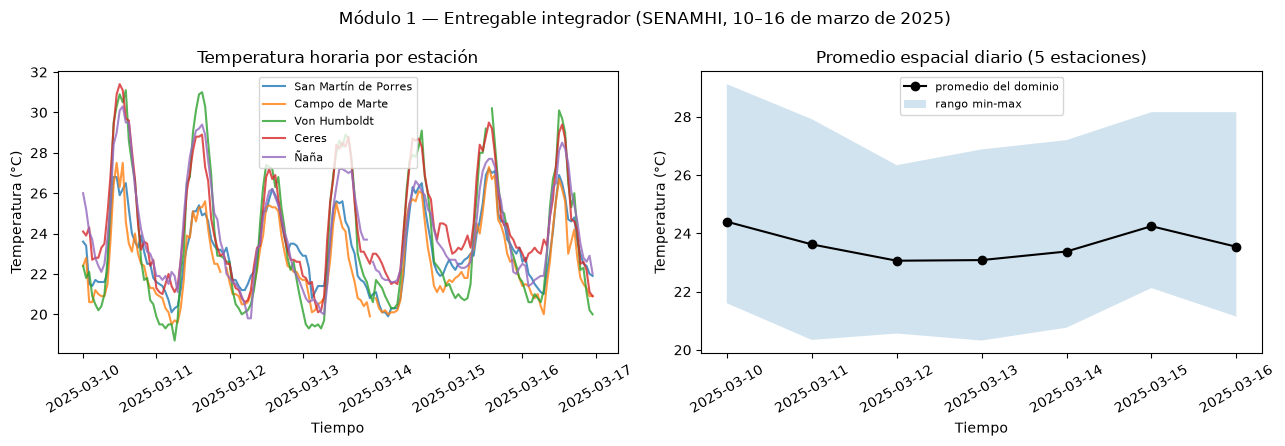

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel izquierdo: series horarias por estación
for nombre in nombres:
    serie = ds["temperatura"].sel(estacion=nombre).to_series()
    axes[0].plot(serie.index, serie.values, label=nombre, alpha=0.8)
axes[0].set_title("Temperatura horaria por estación")
axes[0].set_xlabel("Tiempo")
axes[0].set_ylabel("Temperatura (°C)")
axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", rotation=30)

# Panel derecho: promedio diario del dominio con banda min-max
axes[1].plot(diario.index, diario["promedio"], marker="o", color="black", label="promedio del dominio")
axes[1].fill_between(diario.index, diario["minimo"], diario["maximo"], alpha=0.2, label="rango min-max")
axes[1].set_title("Promedio espacial diario (5 estaciones)")
axes[1].set_xlabel("Tiempo")
axes[1].set_ylabel("Temperatura (°C)")
axes[1].legend(fontsize=8)
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle("Módulo 1 — Entregable integrador (SENAMHI, 10–16 de marzo de 2025)")
fig.tight_layout()
plt.show()

## 6. Exportar el producto final

In [7]:
ds.to_netcdf("entregable_modulo1.nc")
resumen.to_csv("entregable_modulo1_resumen.csv")
print("Archivos generados:")
print(" - entregable_modulo1.nc")
print(" - entregable_modulo1_resumen.csv")

Archivos generados:
 - entregable_modulo1.nc
 - entregable_modulo1_resumen.csv


## 7. ✍️ Tu entregable: el mismo flujo con la humedad relativa

Repite las secciones 1 a 6 para la **humedad relativa** (`"Humedad (%)"`)
de la semana del **17 al 23 de marzo de 2025**. Copia cada celda de arriba
y cambia lo necesario; las líneas marcadas con `✍️` indican dónde.

Ojo: **Ceres no mide humedad** (su archivo no tiene esa columna). Por eso
aquí se usan solo 4 estaciones.

Al final debe quedar en esta carpeta el archivo `entregable_modulo1_mio.nc`
con la variable `humedad` y dimensiones `(tiempo, estacion)`, y una figura
de dos paneles como la de la sección 5.

In [8]:
# ✍️ TU ENTREGABLE — 1. Leer (4 estaciones: todas menos Ceres)
estaciones_h = [e for e in estaciones if e["nombre"] != "Ceres"]
nombres_h = [e["nombre"] for e in estaciones_h]
tiempo_h = None                       # ✍️ 7 días x 24 horas desde el 17 de marzo


def leer_humedad(archivo):
    return None                       # ✍️ como leer_temperatura, pero con la columna "Humedad (%)" y tiempo_h


data_h = None                         # ✍️ np.column_stack([...]) con las 4 estaciones

In [9]:
# ✍️ TU ENTREGABLE — 2 a 4. Dataset, resumen por estación y promedio diario
ds_h = None                           # ✍️ xr.Dataset con la variable "humedad" (units "%") y coordenadas lat, lon, altura
resumen_h = None                      # ✍️ DataFrame con promedio, máximo y mínimo por estación
diario_h = None                       # ✍️ promedio espacial diario con resample("1D")

In [10]:
# ✍️ TU ENTREGABLE — 5. Figura de dos paneles (series por estación + promedio diario con banda)

In [11]:
# ✍️ TU ENTREGABLE — 6. Exportar
# ds_h.to_netcdf("entregable_modulo1_mio.nc")

In [12]:
# ✔️ COMPROBAR — revisa el archivo que exportaste
from pathlib import Path

if not Path("entregable_modulo1_mio.nc").exists():
    print("⏳ Todavía no existe entregable_modulo1_mio.nc (sección 6 de tu entregable).")
else:
    with xr.open_dataset("entregable_modulo1_mio.nc") as mio:
        problemas = []
        if "humedad" not in mio:
            problemas.append("no tiene la variable 'humedad'")
        else:
            h = mio["humedad"]
            if h.dims != ("tiempo", "estacion"):
                problemas.append(f"dimensiones {h.dims}, se esperaba ('tiempo', 'estacion')")
            if mio.sizes.get("tiempo") != 168:
                problemas.append(f"{mio.sizes.get('tiempo')} horas, se esperaban 168 (7 días)")
            if mio.sizes.get("estacion") != 4:
                problemas.append(f"{mio.sizes.get('estacion')} estaciones, se esperaban 4")
            if str(mio["tiempo"].values[0])[:10] != "2025-03-17":
                problemas.append("el tiempo no empieza el 17 de marzo")
            if h.attrs.get("units") != "%":
                problemas.append("falta el atributo units = '%'")
            for coord in ["lat", "lon", "altura"]:
                if coord not in mio.coords:
                    problemas.append(f"falta la coordenada '{coord}'")
        if problemas:
            print("❌ Revisa:", "; ".join(problemas))
        else:
            print("✅ ¡Correcto! Humedad media por estación (%):")
            print(mio["humedad"].mean(dim="tiempo").to_pandas().round(1))

⏳ Todavía no existe entregable_modulo1_mio.nc (sección 6 de tu entregable).


## Conclusión

Leer los datos, estructurarlos con Xarray, resumirlos, agregarlos en el
tiempo, graficarlos y exportarlos: estos pasos se repiten en los módulos
siguientes con otras fuentes de datos. En el Módulo 2 serán archivos
NetCDF y GRIB de modelos y reanálisis. Estas mismas estaciones vuelven en
el Módulo 6, para comparar un pronóstico con lo medido.

**Pregunta de cierre del módulo:** ¿por qué conviene escribir
`ds["temperatura"].sel(estacion="Ceres")` en vez de
`ds["temperatura"].isel(estacion=3)`, si aquí las dos devuelven lo mismo?
*(Respuesta esperada: `.sel` no depende del orden en que se cargaron las
estaciones. Si ese orden cambia, por ejemplo al leer otro archivo,
`.isel(estacion=3)` puede dejar de apuntar a Ceres sin ningún aviso.)*

Siguiente: [Módulo 2 — Formatos de datos atmosféricos](../../modulo_02_formatos_datos_atmosfericos/README.md).